In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

import os
import numpy as np
import matplotlib.pyplot as plt
# import nibabel as nib
import cortex

In [4]:
content_merics = np.load('inference_outputs/NSD/gpt2_xl_semantic_mean_se.npy', allow_pickle=True).item()
style_merics = np.load('inference_outputs/NSD/gpt2_xl_syntax_mean_se.npy', allow_pickle=True).item()
residual_merics = np.load('inference_outputs/NSD/gpt2_xl_residual_mean_se.npy', allow_pickle=True).item()

In [5]:
content_merics = np.load('inference_outputs/NSD/content_mean_se.npy', allow_pickle=True).item()
style_merics = np.load('inference_outputs/NSD/style_mean_se.npy', allow_pickle=True).item()
residual_merics = np.load('inference_outputs/NSD/residual_mean_se.npy', allow_pickle=True).item()

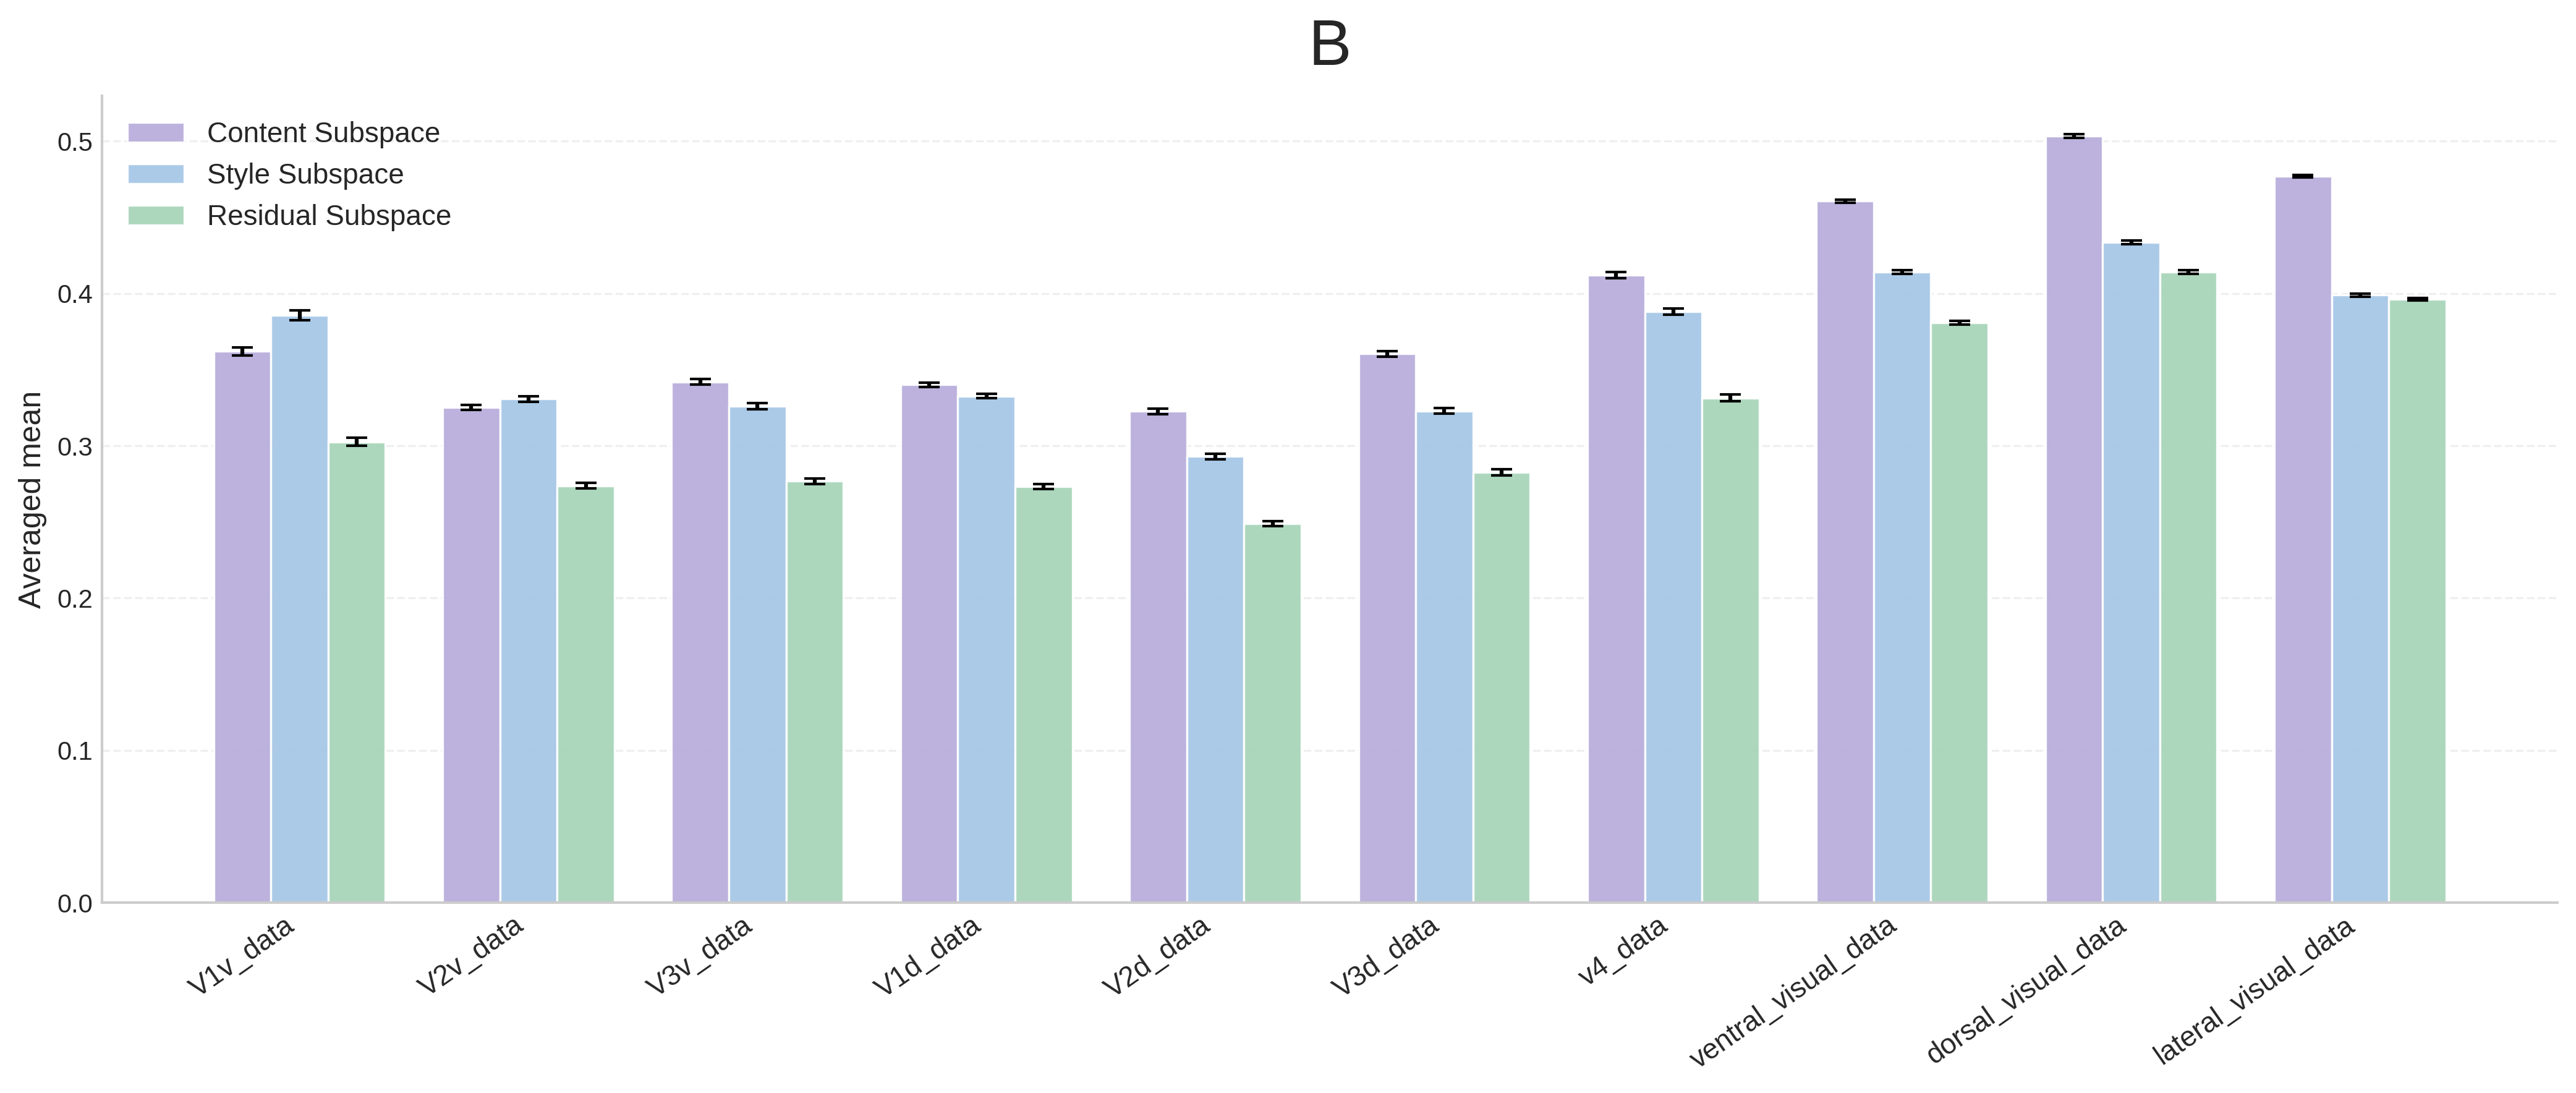

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

regions = list(residual_merics.keys())

def extract_stats(metric_dict):
    means, errs = [], []
    for r in regions:
        mean_vec = np.array(metric_dict[r]['mean'])
        se_vec = np.array(metric_dict[r]['se'])

        mean_val = mean_vec.mean()
        err_val = np.sqrt(np.sum(se_vec**2)) / len(se_vec)

        means.append(mean_val)
        errs.append(err_val)
    return np.array(means), np.array(errs)

res_mean, res_err = extract_stats(residual_merics)
content_mean, content_err = extract_stats(content_merics)
style_mean, style_err = extract_stats(style_merics)

x = np.arange(len(regions))
width = 0.25

# Pastel lavender / blue / green palette
colors = {
    "content": "#B9AEDC",  # lavender
    "style":   "#A7C7E7",  # soft blue
    "residual": "#A8D5BA"   # muted green
}

fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

bar_kws = dict(width=width, capsize=4, alpha=0.95,
               linewidth=0.8, edgecolor="white")

ax.bar(x - width, content_mean, yerr=content_err,
       label='Content Subspace', color=colors["content"], **bar_kws)

ax.bar(x, style_mean, yerr=style_err,
       label='Style Subspace', color=colors["style"], **bar_kws)

ax.bar(x + width, res_mean, yerr=res_err,
       label='Residual Subspace', color=colors["residual"], **bar_kws)

# Axis formatting
ax.set_xticks(x)
ax.set_xticklabels(regions, rotation=35, ha='right', fontsize=11)
ax.set_ylabel("Averaged mean", fontsize=12)
ax.set_title("B", fontsize=25, pad=12)

# Subtle grid styling
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.grid(axis='x', visible=False)

# Clean spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig('neurips_2026_images/nsd_vision.pdf')
plt.show()

In [7]:
residual_merics = np.load('inference_outputs/NSD/gpt2_xl_residual_mean_se.npy', allow_pickle=True).item()
syntax_merics = np.load('inference_outputs/NSD/gpt2_xl_syntax_mean_se.npy', allow_pickle=True).item()
semantic_merics = np.load('inference_outputs/NSD/gpt2_xl_semantic_mean_se.npy', allow_pickle=True).item()

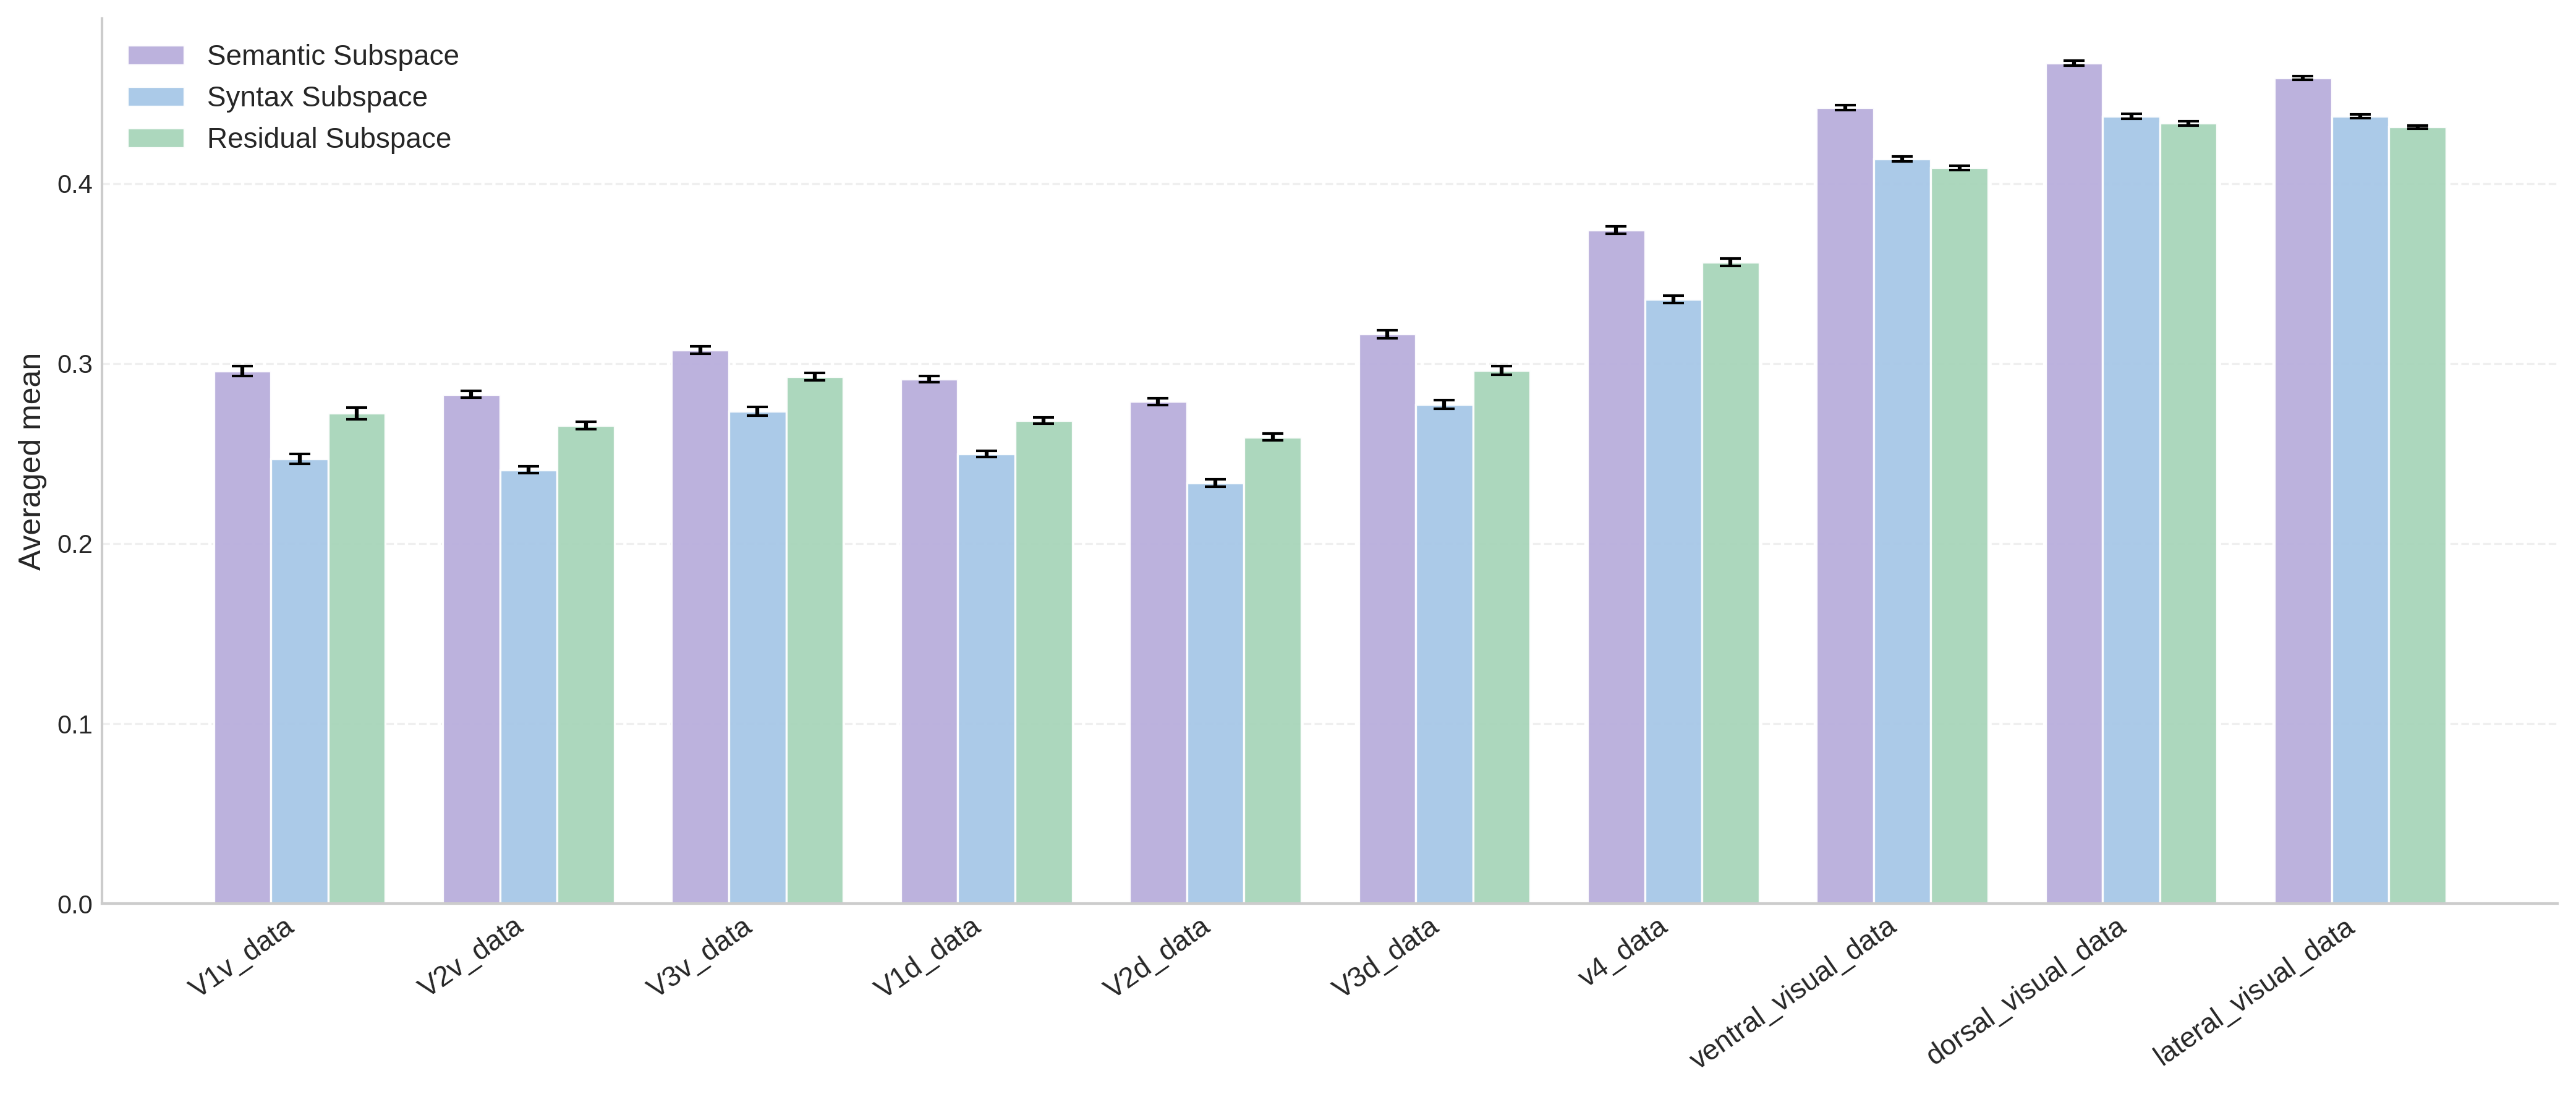

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

regions = list(residual_merics.keys())

def extract_stats(metric_dict):
    means, errs = [], []
    for r in regions:
        mean_vec = np.array(metric_dict[r]['mean'])
        se_vec = np.array(metric_dict[r]['se'])

        mean_val = mean_vec.mean()
        err_val = np.sqrt(np.sum(se_vec**2)) / len(se_vec)

        means.append(mean_val)
        errs.append(err_val)
    return np.array(means), np.array(errs)

res_mean, res_err = extract_stats(residual_merics)
syn_mean, syn_err = extract_stats(syntax_merics)
sem_mean, sem_err = extract_stats(semantic_merics)

x = np.arange(len(regions))
width = 0.25

# Pastel lavender / blue / green palette
colors = {
    "semantic": "#B9AEDC",  # lavender
    "syntax":   "#A7C7E7",  # soft blue
    "residual": "#A8D5BA"   # muted green
}

fig, ax = plt.subplots(figsize=(14, 6), dpi=150)

bar_kws = dict(width=width, capsize=4, alpha=0.95,
               linewidth=0.8, edgecolor="white")

ax.bar(x - width, sem_mean, yerr=sem_err,
       label='Semantic Subspace', color=colors["semantic"], **bar_kws)

ax.bar(x, syn_mean, yerr=syn_err,
       label='Syntax Subspace', color=colors["syntax"], **bar_kws)

ax.bar(x + width, res_mean, yerr=res_err,
       label='Residual Subspace', color=colors["residual"], **bar_kws)

# Axis formatting
ax.set_xticks(x)
ax.set_xticklabels(regions, rotation=35, ha='right', fontsize=11)
ax.set_ylabel("Averaged mean", fontsize=12)
# ax.set_title("D", fontsize=25, pad=12)

# Subtle grid styling
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.grid(axis='x', visible=False)

# Clean spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig('neurips_2026_images/nsd_language.pdf')
plt.show()

# Getting Embeddings

In [9]:
import numpy as np

X = np.load('inference_datasets/NSD_image_embeddings/swinb/0.4375_0.4375/invertible/content/25.npy')

In [10]:
from utils.dataloader import *
from utils.models_util import *
from utils.loss_utils import *

import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

with open("raw_training_data/pereira_2018/syntactic_paraphrases_70_gemini.json", "r") as f:
    syntactic_paraphrases = json.load(f)

with open("raw_training_data/pereira_2018/paraphrases_70_gemini.json", "r") as f:
    paraphrases = json.load(f)

layer = 47
transformation_type = 'invertible'
model_name = 'gpt2_xl'

model = Disentangled_Invertible_Language_Model(model_name, layer, 'avg', 0.01, transformation_type).cuda()
model.load_state_dict(torch.load('language_outputs/' + transformation_type + '/msr_paraphrase_corpus_'+model_name+'_0.01_'+str(layer)+'_avg_'+transformation_type+'_0.4_0.4/last_best_model.pt'))

/home/khoslalab/anaconda3/envs/RPO/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

Using invertible transformation


<All keys matched successfully>

In [2]:
import pickle
import json
import numpy as np

splits = np.load('inference_datasets/NSD_image_embeddings/splits/splits_0.npy', allow_pickle=True).item()
all = np.concatenate((splits['train'], splits['test']))

with open('/home/khoslalab/Documents/response-optimised-models/data/coco/annotations/captions_train2017.json', 'r') as f:
    data = json.load(f)

captions = {}

for annotation in data['annotations']:
    if annotation['image_id'] in all:
        captions[annotation['image_id']] = annotation['caption']

In [5]:
from tqdm import tqdm

semantic_subspace = {}
syntactic_subspace = {}
residual_subspace = {}
                    

for id in tqdm(captions):
    x = captions[id]
    outputs = model(x)
    semantic, syntactic, residual = torch.split(outputs, [int(0.4*1600), int(0.4*1600), int(0.2*1600)], dim=1)
    np.save('inference_datasets/NSD_image_embeddings/gpt2_xl/0.4_0.4/invertible/semantic/'+str(id)+'.npy', semantic.cpu().detach().numpy())
    np.save('inference_datasets/NSD_image_embeddings/gpt2_xl/0.4_0.4/invertible/syntax/'+str(id)+'.npy', syntactic.cpu().detach().numpy())
    np.save('inference_datasets/NSD_image_embeddings/gpt2_xl/0.4_0.4/invertible/residual/'+str(id)+'.npy', residual.cpu().detach().numpy())

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:22<00:00, 44.94it/s]


In [7]:
semantic.shape

torch.Size([1, 640])

# Which areas of the visual cortex are better predicted by content subspace versus style subspace, or syntax versus semantic subspace?

In [11]:
content_ventral = content_merics['ventral_visual_data']['mean']
style_ventral = style_merics['ventral_visual_data']['mean']
better_content = np.where(content_ventral > style_ventral, 2, 3)
better_content_sub1 = better_content[:5931] ## Number of valid voxels
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/ventral_visual_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_ventral = np.ones(nc01.shape)
voxel_splits_ventral[valid_voxels_ids] = better_content_sub1


# -------- dorsal --------
content_dorsal = content_merics['dorsal_visual_data']['mean']
style_dorsal = style_merics['dorsal_visual_data']['mean']
better_content = np.where(content_dorsal > style_dorsal, 2, 3)
better_content_sub1 = better_content[:3233]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/dorsal_visual_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_dorsal = np.ones(nc01.shape)
voxel_splits_dorsal[valid_voxels_ids] = better_content_sub1


# -------- lateral --------
content_lateral = content_merics['lateral_visual_data']['mean']
style_lateral = style_merics['lateral_visual_data']['mean']
better_content = np.where(content_lateral > style_lateral, 2, 3)
better_content_sub1 = better_content[:6680]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/lateral_visual_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_lateral = np.ones(nc01.shape)
voxel_splits_lateral[valid_voxels_ids] = better_content_sub1


# -------- V1v --------
content_V1v = content_merics['V1v_data']['mean']
style_V1v = style_merics['V1v_data']['mean']
better_content = np.where(content_V1v > style_V1v, 2, 3)
better_content_sub1 = better_content[:588]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V1v_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_V1v = np.ones(nc01.shape)
voxel_splits_V1v[valid_voxels_ids] = better_content_sub1


# -------- V1d --------
content_V1d = content_merics['V1d_data']['mean']
style_V1d = style_merics['V1d_data']['mean']
better_content = np.where(content_V1d > style_V1d, 2, 3)
better_content_sub1 = better_content[:747]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V1d_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_V1d = np.ones(nc01.shape)
voxel_splits_V1d[valid_voxels_ids] = better_content_sub1


# -------- V2v --------
content_V2v = content_merics['V2v_data']['mean']
style_V2v = style_merics['V2v_data']['mean']
better_content = np.where(content_V2v > style_V2v, 2, 3)
better_content_sub1 = better_content[:801]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V2v_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_V2v = np.ones(nc01.shape)
voxel_splits_V2v[valid_voxels_ids] = better_content_sub1


# -------- V2d --------
content_V2d = content_merics['V2d_data']['mean']
style_V2d = style_merics['V2d_data']['mean']
better_content = np.where(content_V2d > style_V2d, 2, 3)
better_content_sub1 = better_content[:587]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V2d_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_V2d = np.ones(nc01.shape)
voxel_splits_V2d[valid_voxels_ids] = better_content_sub1


# -------- V3v --------
content_V3v = content_merics['V3v_data']['mean']
style_V3v = style_merics['V3v_data']['mean']
better_content = np.where(content_V3v > style_V3v, 2, 3)
better_content_sub1 = better_content[:625]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V3v_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_V3v = np.ones(nc01.shape)
voxel_splits_V3v[valid_voxels_ids] = better_content_sub1


# -------- V3d --------
content_V3d = content_merics['V3d_data']['mean']
style_V3d = style_merics['V3d_data']['mean']
better_content = np.where(content_V3d > style_V3d, 2, 3)
better_content_sub1 = better_content[:531]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V3d_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_V3d = np.ones(nc01.shape)
voxel_splits_V3d[valid_voxels_ids] = better_content_sub1


# -------- v4 --------
content_v4 = content_merics['v4_data']['mean']
style_v4 = style_merics['v4_data']['mean']
better_content = np.where(content_v4 > style_v4, 2, 3)
better_content_sub1 = better_content[:661]
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/v4_data/nc_01.npy')
valid_voxels_ids = np.array([i for i in range(len(nc01)) if nc01[i]>0])
voxel_splits_v4 = np.ones(nc01.shape)
voxel_splits_v4[valid_voxels_ids] = better_content_sub1

/tmp/ipykernel_2124263/2103386308.py:133: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.08, 1, 0.92])


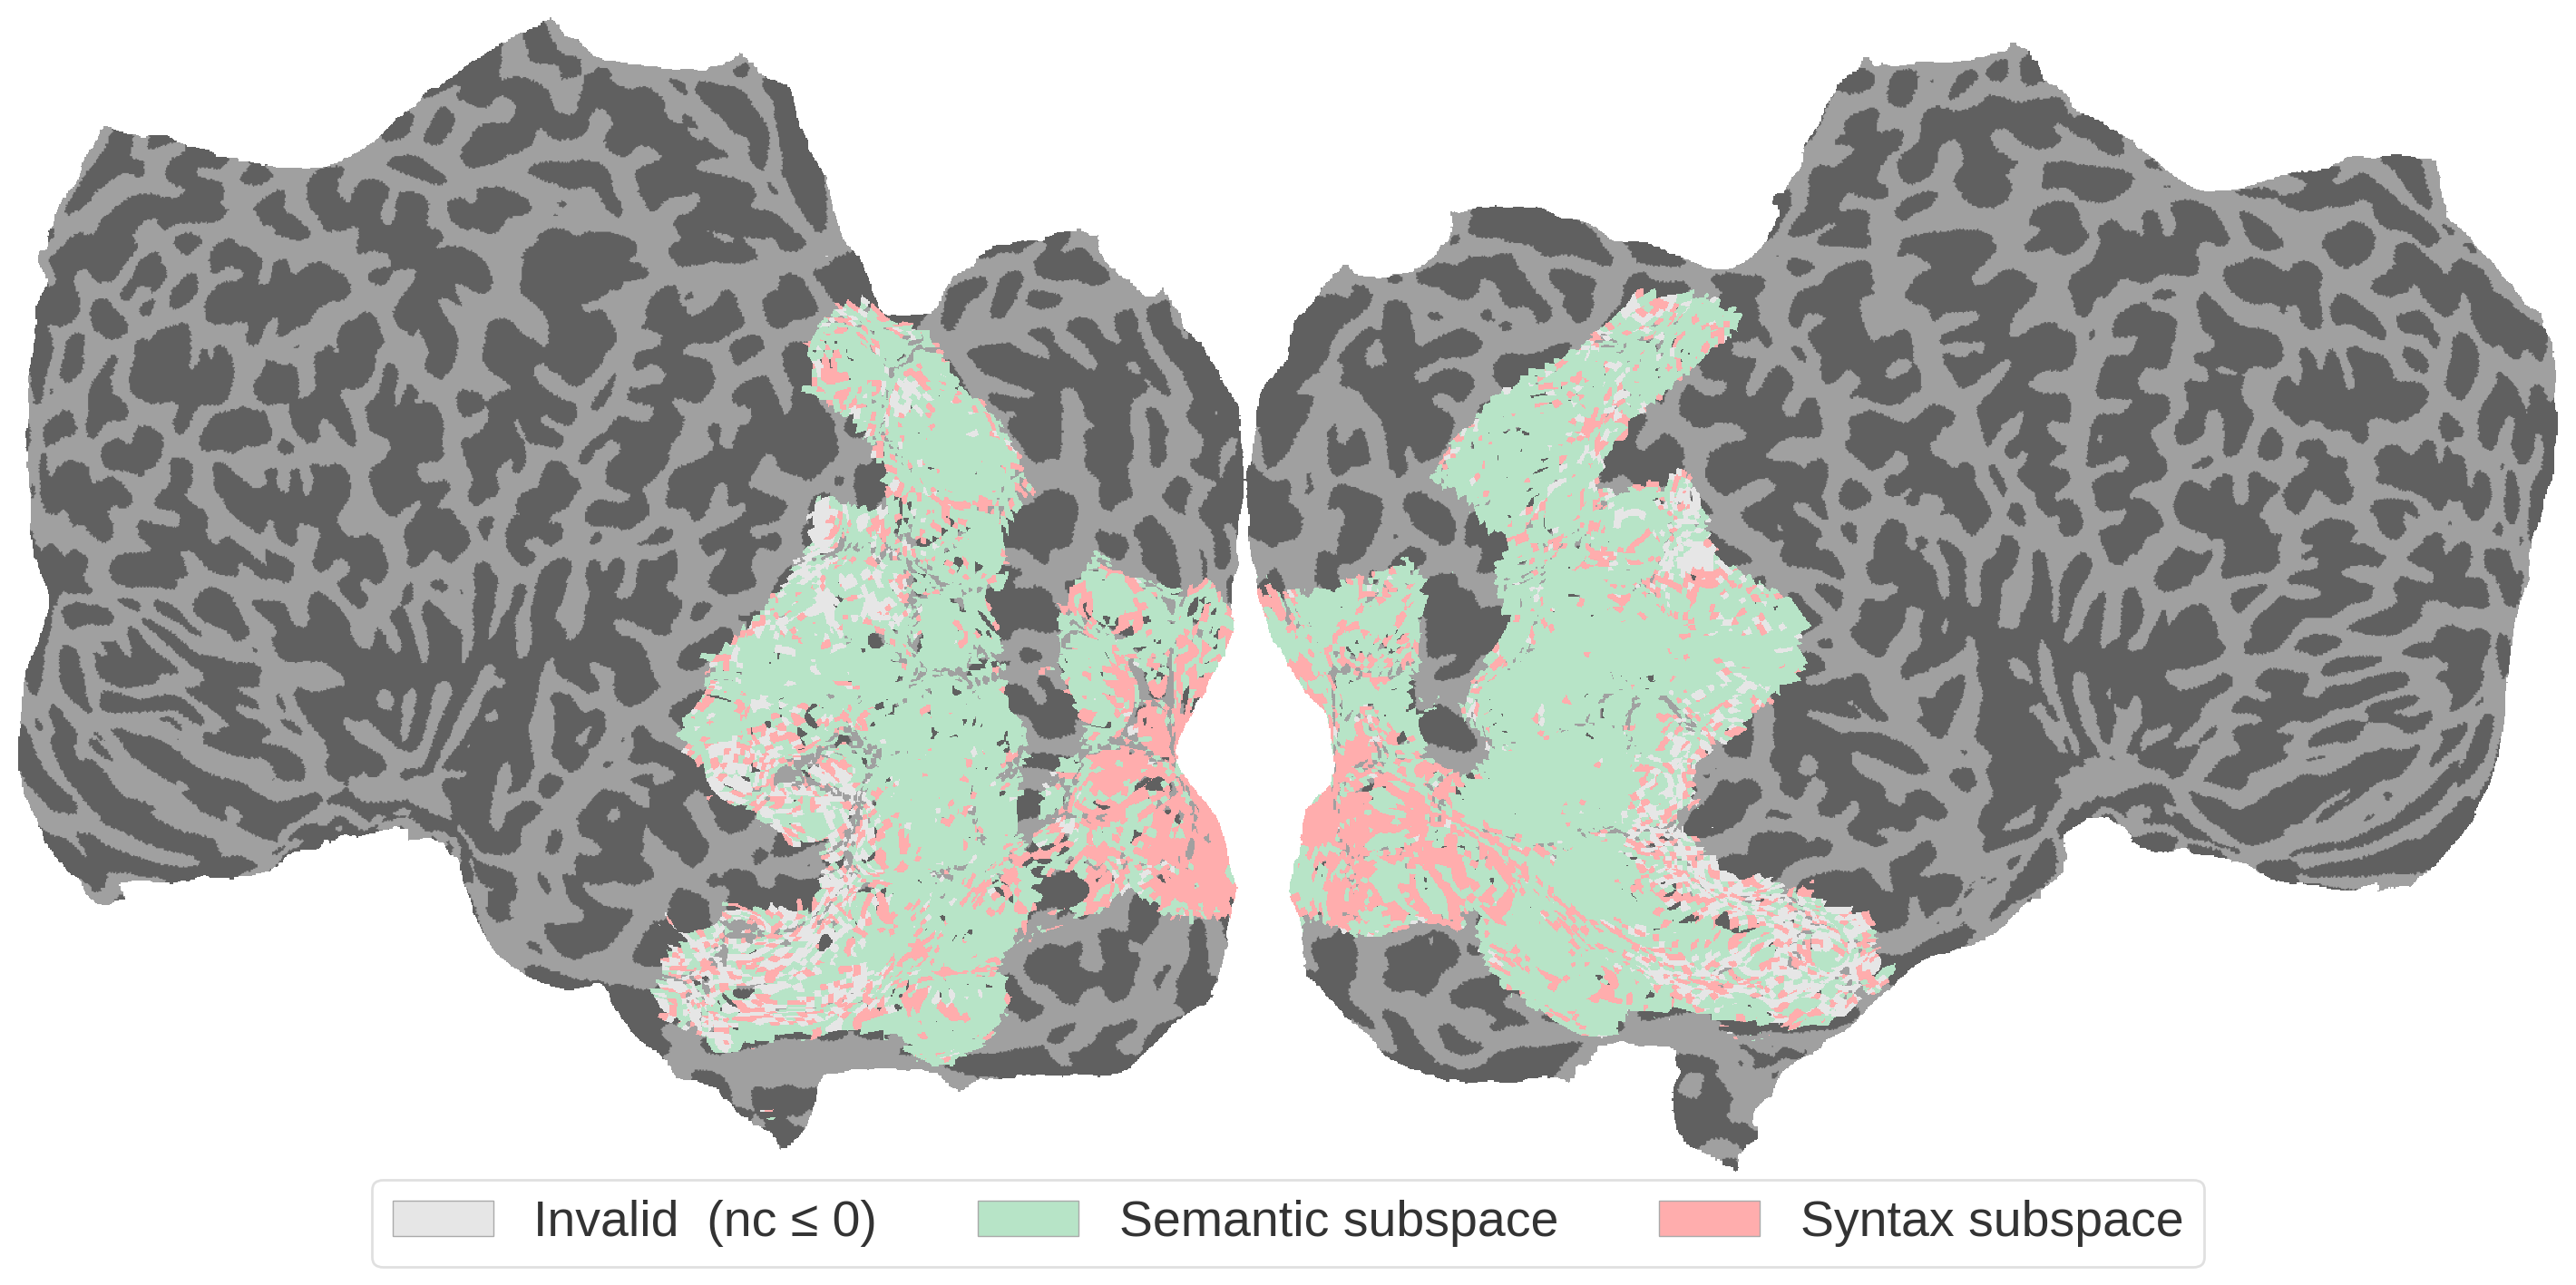

In [13]:
import cortex
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm

# ── subject / transform ──────────────────────────────────────────────────────
subj    = 1
subject = "subj%02d" % subj
xfm     = 'func1pt8_to_anat0pt8_autoFSbbr'

# ── masks ────────────────────────────────────────────────────────────────────
base_dir = '/home/khoslalab/Documents/response-optimised-models/data'

basic_mask      = np.load(f'{base_dir}/masks/subj{subj}/cortical_mask_subj{subj:02d}.npy')
cortical_mask   = np.load(f'{base_dir}/masks/subj{subj}/cortical_mask_subj{subj:02d}.npy')
streams_mask    = np.load(f'{base_dir}/masks/subj{subj}/roi_1d_mask_subj{subj:02d}_streams.npy')
visualrois_mask = np.load(f'{base_dir}/masks/subj{subj}/roi_1d_mask_subj{subj:02d}_prf-visualrois.npy')

# ── build data_val ───────────────────────────────────────────────────────────
# values:  1 = invalid (nc ≤ 0)  |  2 = content  |  3 = style
data_val = np.full(streams_mask.shape, np.nan)

# streams
data_val[streams_mask == 5] = voxel_splits_ventral
data_val[streams_mask == 6] = voxel_splits_lateral
data_val[streams_mask == 7] = voxel_splits_dorsal

# visual ROIs  (1=V1v 2=V1d 3=V2v 4=V2d 5=V3v 6=V3d 7=hV4)
roi_map = {
    1: voxel_splits_V1v,
    2: voxel_splits_V1d,
    3: voxel_splits_V2v,
    4: voxel_splits_V2d,
    5: voxel_splits_V3v,
    6: voxel_splits_V3d,
    7: voxel_splits_v4,
}
for roi_id, splits in roi_map.items():
    data_val[visualrois_mask == roi_id] = splits

# ── map into cortical volume ──────────────────────────────────────────────────
new_mask = np.full(cortical_mask.shape, np.nan)
new_mask[basic_mask] = data_val.copy()
new_mask = np.transpose(new_mask, (2, 1, 0))

# ── pastel colormap ──────────────────────────────────────────────────────────
cmap_colors = [
    '#E6E6E6',   # soft grey (invalid)
    '#B7E4C7',   # pastel green (content)
    '#FFADAD',   # pastel red (style)
]
cmap = ListedColormap(cmap_colors)
norm = BoundaryNorm(boundaries=[0.5, 1.5, 2.5, 3.5], ncolors=3)


# ── cortex volume ─────────────────────────────────────────────────────────────
vol = cortex.Volume(
    new_mask.copy(),
    subject, xfm,
    vmin=1, vmax=3,
    cmap=cmap,
    with_curvature=True,
    with_sulci=True,
)

# ── flat map figure ───────────────────────────────────────────────────────────
fig = cortex.quickflat.make_figure(
    vol,
    sampler='nearest',
    thick=1,
    with_colorbar=False,
    with_curvature=True,
    with_rois=False,
    with_labels=False,
    with_sulci=False,
)

# ── figure styling ────────────────────────────────────────────────────────────
fig.set_size_inches(14, 8)
fig.patch.set_facecolor('white')
# fig.text(
#     0.5, 0.9,
#     'A',
#     ha='left', va='top',
#     fontsize=25, fontweight='bold',
#     color='#333333',
# )

# Optional titles (kept commented as in original)
# fig.text(
#     0.5, 0.97,
#     f'Better-Fitting Model per Voxel — Subject {subj:02d}',
#     ha='center', va='top',
#     fontsize=16, fontweight='bold',
#     color='#333333',
# )
# fig.text(
#     0.5, 0.93,
#     'Content model vs. Style model  |  grey = invalid voxels (nc ≤ 0)',
#     ha='center', va='top',
#     fontsize=10, color='#666666',
# )

# ── legend ────────────────────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(facecolor='#E6E6E6', edgecolor='#AAAAAA', linewidth=0.5,
                   label='Invalid  (nc ≤ 0)'),
    mpatches.Patch(facecolor='#B7E4C7', edgecolor='#AAAAAA', linewidth=0.5,
                   label='Semantic subspace'),
    mpatches.Patch(facecolor='#FFADAD', edgecolor='#AAAAAA', linewidth=0.5,
                   label='Syntax subspace'),
]

legend = fig.legend(
    handles=legend_patches,
    loc='lower center',
    ncol=3,
    frameon=True,
    framealpha=0.9,
    edgecolor='#DDDDDD',
    facecolor='white',
    fontsize=20,
    # title='Voxel class',
    title_fontsize=12,
    bbox_to_anchor=(0.5, 0.02),
    labelcolor='#333333',
)

legend.get_title().set_color('#333333')

# ── layout + save ─────────────────────────────────────────────────────────────
plt.tight_layout(rect=[0, 0.08, 1, 0.92])

plt.savefig(
    f'neurips_2026_images/swinb_voxel_splits_subj{subj:02d}.pdf',
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

# Noise Celing

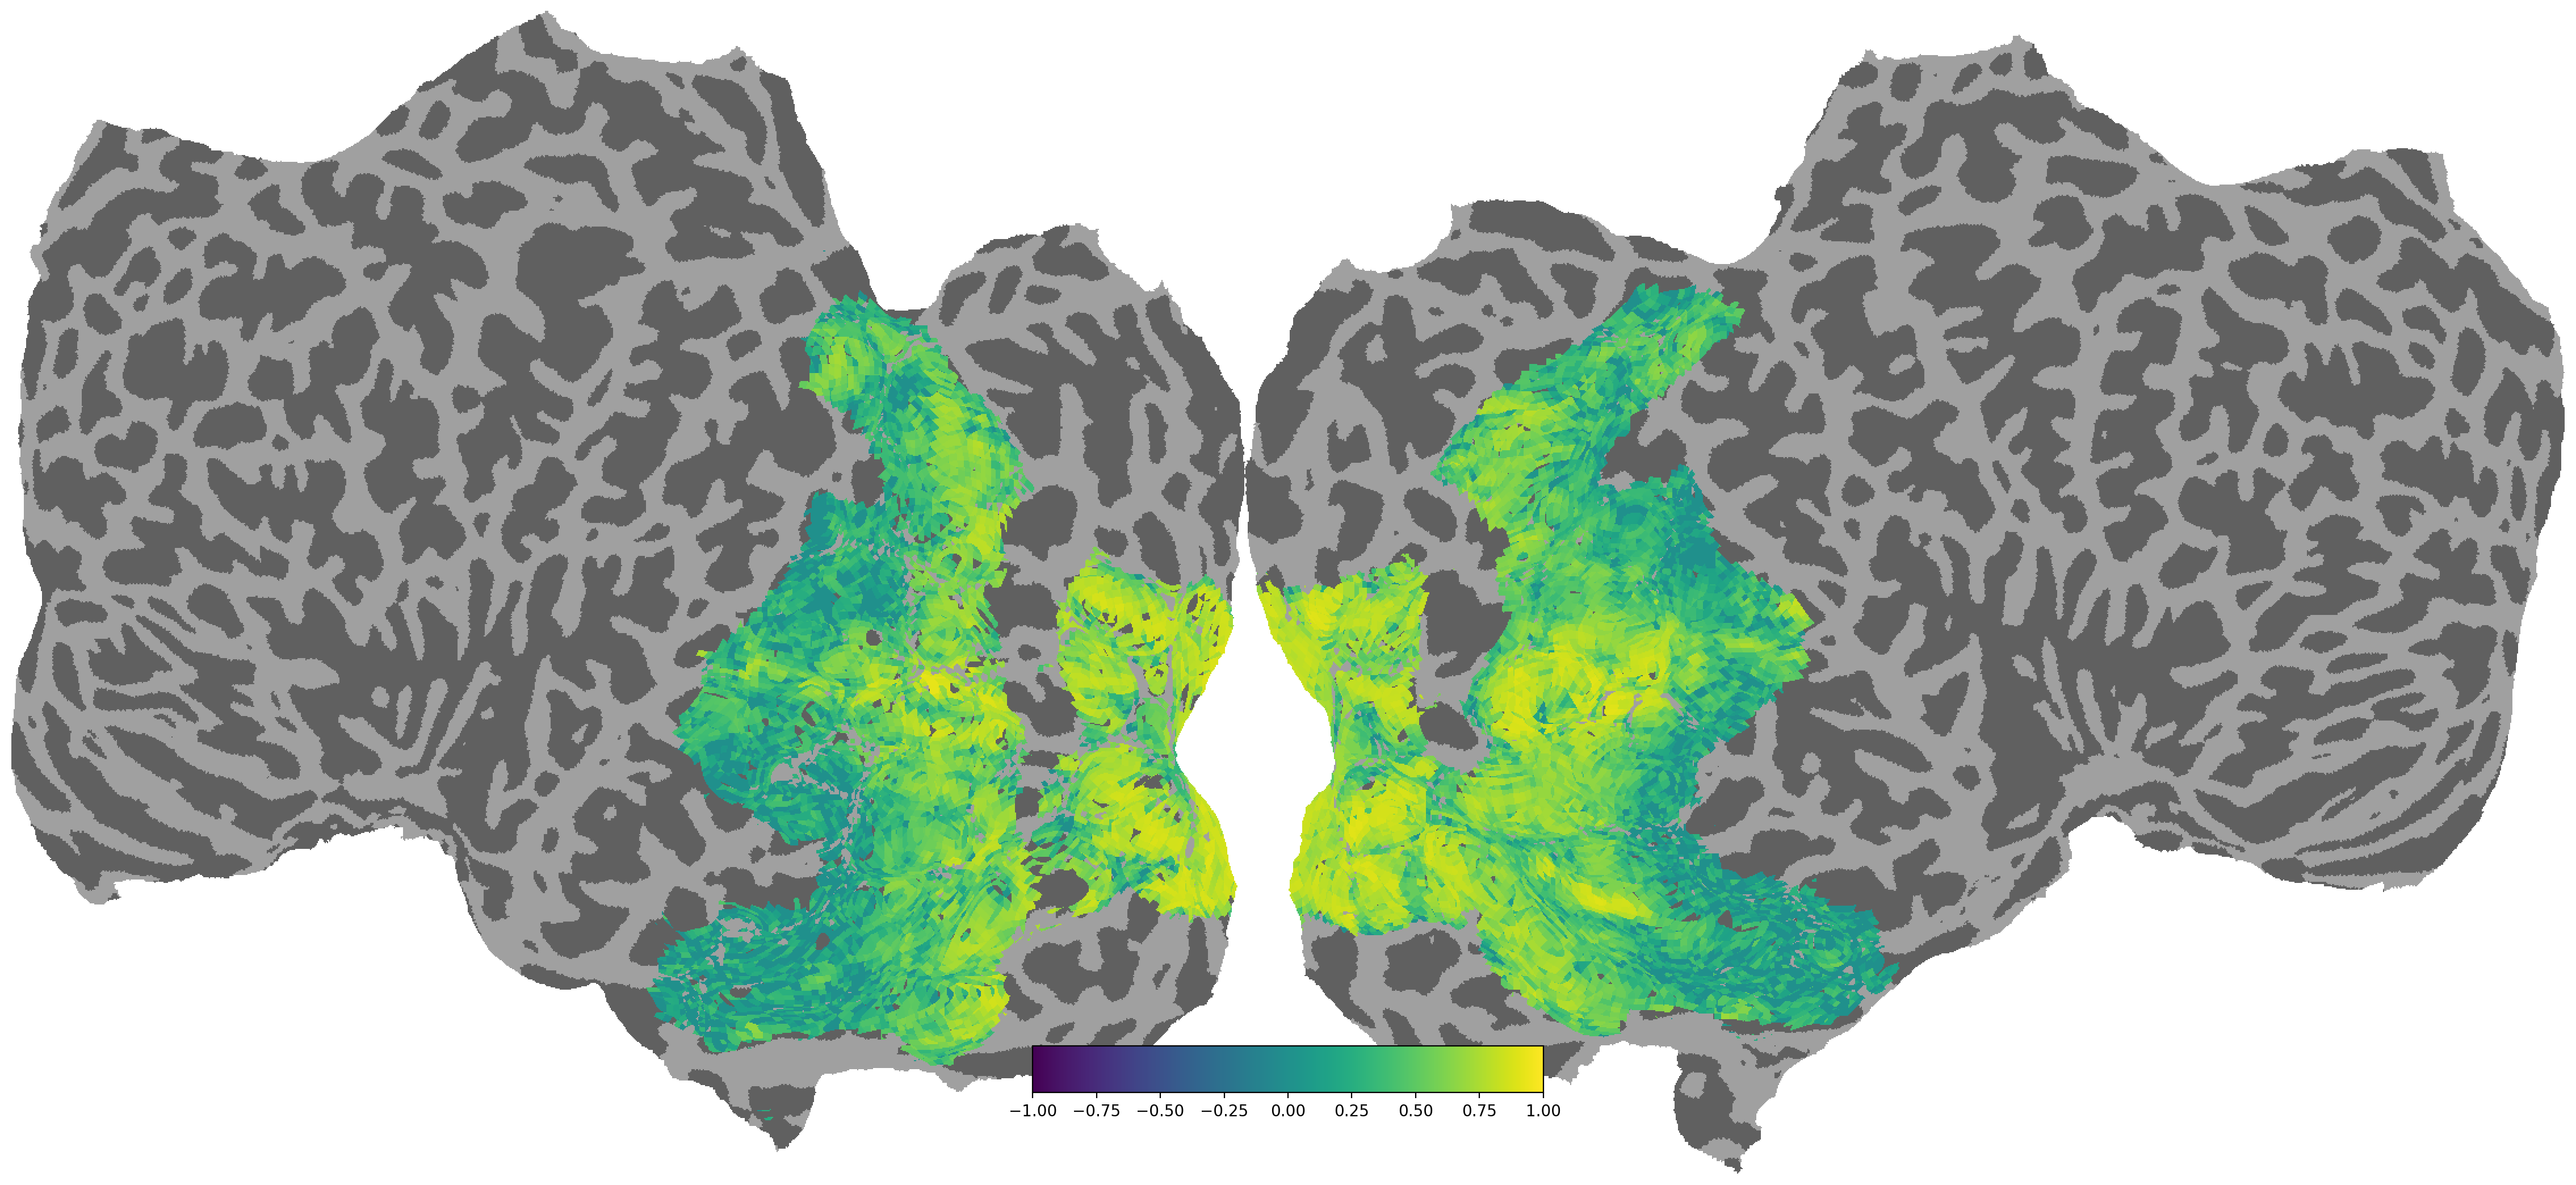

In [3]:
subj = 1
subject = "subj%02d"%subj
xfm = 'func1pt8_to_anat0pt8_autoFSbbr' 

basic_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/cortical_mask_subj%02d.npy'%(subj, subj)) 
streams_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_streams.npy'%(subj, subj)) 
cortical_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/cortical_mask_subj%02d.npy'%(subj, subj)) 


data_val = np.zeros(streams_mask.shape)
data_val[:] = np.nan
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/lateral_visual_data/nc_01.npy')
data_val[streams_mask == 6] = nc01 # 1: <=0 nc, 2: 'bad', 3: 'good'
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/ventral_visual_data/nc_01.npy')
data_val[streams_mask == 5] = nc01 # 1: <=0 nc, 2: 'bad', 3: 'good'
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/dorsal_visual_data/nc_01.npy')
data_val[streams_mask == 7] = nc01 # 1: <=0 nc, 2: 'bad', 3: 'good'



roi = 1 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V1v_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

roi = 2 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V1d_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

roi = 3 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V2v_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

roi = 4 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V2d_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

roi = 5 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V3v_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

roi = 6 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/V3d_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

roi = 7 ## 1: V1v, 2: V1d, 3: V2v, 4: V2d, 5: V3v, 6: V3d, and 7: hV4
visualrois_mask = np.load('/home/khoslalab/Documents/response-optimised-models/data/masks/subj%d/roi_1d_mask_subj%02d_prf-visualrois.npy'%(subj, subj))
nc01 = np.load('/home/khoslalab/Documents/response-optimised-models/data/v4_data/nc_01.npy')
data_val[visualrois_mask == roi] = nc01

new_data_val = data_val.copy()

new_mask = np.zeros(cortical_mask.shape) 
new_mask[:] = np.nan
new_mask[basic_mask] = new_data_val.copy()
new_mask = np.transpose(new_mask, (2, 1, 0)) 
vol_data_nan = cortex.Volume(new_mask.copy(), subject, xfm, vmin = -1, vmax = 1, cmap="viridis", with_curvature = True, with_sulci = True)

fig = cortex.quickflat.make_figure(vol_data_nan, sampler='nearest', thick = 1,
                                       with_curvature=True,
                                       with_rois=False,
                                       with_labels=False,
                                      with_sulci=False)

plt.show()